# Galaxy image preparation

Prepare a balanced spiral-versus-elliptical image dataset for a CNN.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from sklearn.model_selection import train_test_split

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / 'scripts' / 'cutouts.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'scripts' / 'cutouts.py').exists():
    raise FileNotFoundError('Could not locate the repository root.')
sys.path.insert(0, str(ROOT))

import importlib
import scripts.data_processing as dp
import scripts.cutouts as cutouts
cutouts = importlib.reload(cutouts)
dataset = dp.load_data(ROOT / 'datasets' / 'processed_datasets' / 'galaxies_clean.csv')
print(f'Repository: {ROOT}')
print(f'Catalogue rows: {len(dataset):,}')

Repository: /Users/tomasaspa/Desktop/IFAE/Repositories/galaxies_cnns
Catalogue rows: 241,659


## Select a balanced CNN starter set

1,000 objects per class, split 70% train, 15% validation, and 15% test.

In [2]:
SAMPLES_PER_CLASS = 1_000
RANDOM_STATE = 42
subset = dataset.loc[dataset['spiral'].isin([0, 1])].copy()
subset['label'] = (subset['spiral'] > subset['elliptical']).astype(int)
subset = pd.concat([
    subset[subset['label'] == label].sample(n=SAMPLES_PER_CLASS, random_state=RANDOM_STATE)
    for label in (0, 1)
], ignore_index=True)
train_ids, remainder_ids = train_test_split(
    subset['specobjid'], test_size=0.30, stratify=subset['label'], random_state=RANDOM_STATE
)
remainder = subset[subset['specobjid'].isin(remainder_ids)]
validation_ids, test_ids = train_test_split(
    remainder['specobjid'], test_size=0.50, stratify=remainder['label'], random_state=RANDOM_STATE
)
subset['split'] = 'test'
subset.loc[subset['specobjid'].isin(train_ids), 'split'] = 'train'
subset.loc[subset['specobjid'].isin(validation_ids), 'split'] = 'validation'
print(subset.groupby(['split', 'label']).size().unstack(fill_value=0))

label         0    1
split               
test        150  150
train       700  700
validation  150  150


## Download cutouts

Images are stored in `datasets/images/cutouts_cnn.sqlite` as JPEG BLOBs. Rerunning this cell resumes safely.

In [3]:
database = ROOT / 'datasets' / 'images' / 'cutouts_cnn.sqlite'
cutouts.prepare_manifest(subset, database, provider='hips2fits', width=128, height=128)
print('Database:', database.resolve())
print('Before download:', cutouts.status(database))
downloaded, failed = cutouts.download_pending(
    database, workers=16, retries=1, retry_errors=True, progress_every=100
)
print(f'Downloaded: {downloaded}; failed: {failed}')

Database: /Users/tomasaspa/Desktop/IFAE/Repositories/galaxies_cnns/datasets/images/cutouts_cnn.sqlite
Before download: {'pending': 2000}
Progress: 100/2000 (5%); successful=100; failed=0
Progress: 200/2000 (10%); successful=200; failed=0
Progress: 300/2000 (15%); successful=300; failed=0
Progress: 400/2000 (20%); successful=400; failed=0
Progress: 500/2000 (25%); successful=500; failed=0
Progress: 600/2000 (30%); successful=600; failed=0
Progress: 700/2000 (35%); successful=700; failed=0
Progress: 800/2000 (40%); successful=800; failed=0
Progress: 900/2000 (45%); successful=900; failed=0
Progress: 1000/2000 (50%); successful=1000; failed=0
Progress: 1100/2000 (55%); successful=1100; failed=0
Progress: 1200/2000 (60%); successful=1200; failed=0
Progress: 1300/2000 (65%); successful=1300; failed=0
Progress: 1400/2000 (70%); successful=1400; failed=0
Progress: 1500/2000 (75%); successful=1500; failed=0
Progress: 1600/2000 (80%); successful=1600; failed=0
Progress: 1700/2000 (85%); success

## Download quality-control dashboard

Database: /Users/tomasaspa/Desktop/IFAE/Repositories/galaxies_cnns/datasets/images/cutouts_cnn.sqlite
Download status:


,status,count
0,downloaded,2000


Downloaded images by split and label:


,split,label,count
0,test,0,150
1,test,1,150
2,train,0,700
3,train,1,700
4,validation,0,150
5,validation,1,150


Downloaded image byte sizes:


,min_bytes,mean_bytes,max_bytes
0,3907,4062,4389


Image dimensions found: [(128, 128)]


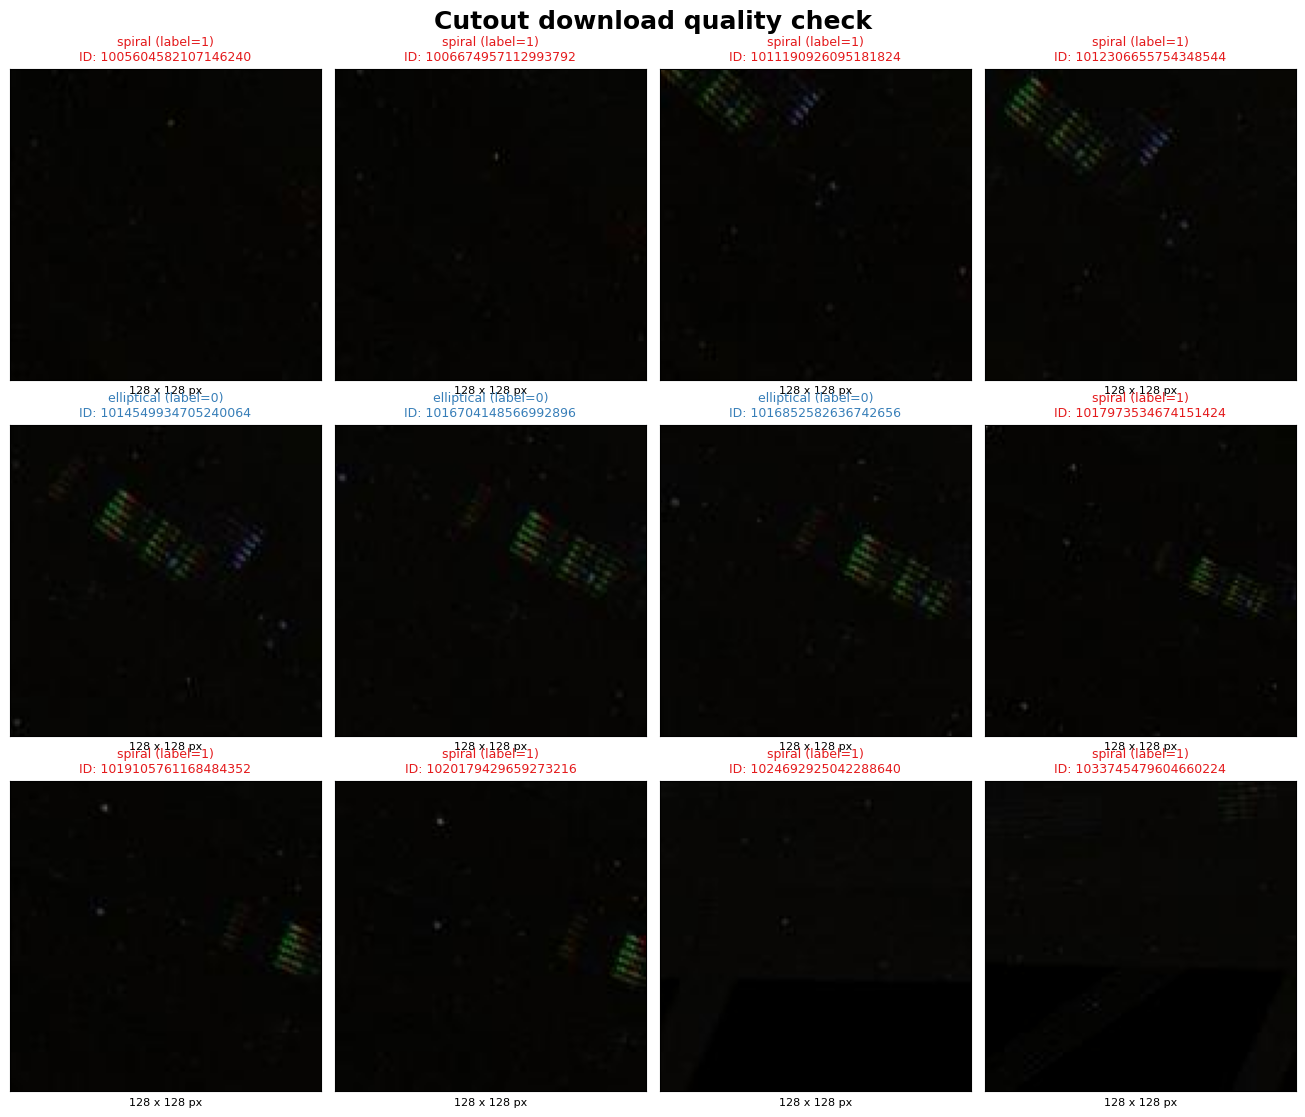

In [4]:
import sqlite3
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt
from scripts.cutouts import iter_images

connection = sqlite3.connect(database)
status_counts = pd.read_sql_query('SELECT status, COUNT(*) AS count FROM cutouts GROUP BY status', connection)
split_counts = pd.read_sql_query(
    "SELECT split, label, COUNT(*) AS count FROM cutouts WHERE status='downloaded' GROUP BY split, label ORDER BY split, label",
    connection,
)
byte_sizes = pd.read_sql_query(
    'SELECT MIN(LENGTH(image)) AS min_bytes, AVG(LENGTH(image)) AS mean_bytes, MAX(LENGTH(image)) AS max_bytes FROM cutouts WHERE status="downloaded"',
    connection,
)
connection.close()
samples = list(iter_images(database, split='train'))[:12]
if not samples:
    raise RuntimeError('No downloaded training images are available.')
decoded = [(object_id, Image.open(BytesIO(blob)).convert('RGB'), label) for object_id, blob, label in samples]
print('Database:', database.resolve())
print('Download status:')
display(status_counts)
print('Downloaded images by split and label:')
display(split_counts)
print('Downloaded image byte sizes:')
display(byte_sizes.round(0).astype('Int64'))
print('Image dimensions found:', sorted({image.size for _, image, _ in decoded}))

fig, axes = plt.subplots(3, 4, figsize=(13, 11), constrained_layout=True)
fig.suptitle('Cutout download quality check', fontsize=18, fontweight='bold')
names = {0: 'elliptical', 1: 'spiral'}
colors = {0: '#377eb8', 1: '#e41a1c'}
for axis, (object_id, image, label) in zip(axes.flat, decoded):
    axis.imshow(image)
    axis.set_title(f'{names[label]} (label={label})\nID: {object_id}', color=colors[label], fontsize=9)
    axis.set_xlabel(f'{image.size[0]} x {image.size[1]} px', fontsize=8)
    axis.set_xticks([])
    axis.set_yticks([])
for axis in axes.flat[len(decoded):]:
    axis.axis('off')
plt.show()